# Exploratory Data Analysis

EDA untuk lima dataset.

## Import import

In [8]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
DATASET_DIR = Path('dataset')

In [9]:
df_lev = pd.read_csv(DATASET_DIR / 'oc05_lev.csv')
df_nhanes = pd.read_csv(DATASET_DIR / 'oc05_nhanes.csv')
df_esl = pd.read_csv(DATASET_DIR / 'oc06_esl.csv')
df_student = pd.read_csv(DATASET_DIR / 'oc08_studentPerformance.csv')
df_airbnb = pd.read_csv(DATASET_DIR / 'oc10_melbourneAirbnb.csv')

print('Semua dataset berhasil dimuat.')

Semua dataset berhasil dimuat.


## 1. Melbourne Airbnb

Listing Airbnb di Melbourne, Targetnya kategori harga dari rendah sampai tinggi.

In [26]:
print('Ukuran:', df_airbnb.shape)
display(df_airbnb.head())
df_airbnb.info()

Ukuran: (20036, 49)


,accommodates,availability_30,availability_365,availability_60,availability_90,bathrooms,bed_type,bedrooms,beds,calculated_host_listings_count,...,latitude,license,longitude,maximum_nights,minimum_nights,number_of_reviews,require_guest_phone_verification,require_guest_profile_picture,room_type,y
0,4,0,103,0,23,1.0,4.0,2.0,2.0,3,...,-37.770973,-1.0,145.010506,30,2,1,0,1,0.0,5
1,2,11,339,34,64,1.0,4.0,1.0,1.0,27,...,-37.823365,-1.0,144.966454,1125,7,22,0,0,0.0,8
2,3,3,84,6,12,1.0,4.0,1.0,2.0,4,...,-37.819387,-1.0,144.954577,1125,1,133,0,0,0.0,8
3,2,0,0,0,0,1.5,4.0,1.0,1.0,1,...,-37.806977,-1.0,144.954666,1125,1,1,0,0,1.0,2
4,4,2,179,2,2,1.5,4.0,2.0,2.0,1,...,-37.755833,-1.0,145.041916,180,2,38,0,0,0.0,7


<class 'pandas.DataFrame'>
RangeIndex: 20036 entries, 0 to 20035
Data columns (total 49 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   accommodates                              20036 non-null  int64  
 1   availability_30                           20036 non-null  int64  
 2   availability_365                          20036 non-null  int64  
 3   availability_60                           20036 non-null  int64  
 4   availability_90                           20036 non-null  int64  
 5   bathrooms                                 20036 non-null  float64
 6   bed_type                                  20036 non-null  float64
 7   bedrooms                                  20036 non-null  float64
 8   beds                                      20036 non-null  float64
 9   calculated_host_listings_count            20036 non-null  int64  
 10  calendar_updated                          200

### Kualitas data

In [27]:
missing_airbnb = df_airbnb.isna().sum().sort_values(ascending=False).rename('missing')
display(missing_airbnb[missing_airbnb > 0].to_frame())
print('Duplikat:', df_airbnb.duplicated().sum())

,missing


Duplikat: 0


### Statistik dan distribusi target

,count,mean,std,min,25%,50%,75%,max
accommodates,20036.0,3.442304,2.224468,1.000000,2.000000,2.000000,4.000000,1.600000e+01
availability_30,20036.0,10.201887,10.435270,0.000000,0.000000,7.000000,19.000000,3.000000e+01
availability_365,20036.0,134.642893,132.882472,0.000000,4.000000,87.000000,273.000000,3.650000e+02
availability_60,20036.0,23.722100,21.376442,0.000000,0.000000,21.000000,42.000000,6.000000e+01
availability_90,20036.0,39.096177,32.937196,0.000000,0.000000,38.000000,69.000000,9.000000e+01
bathrooms,20036.0,1.292798,0.584470,0.000000,1.000000,1.000000,1.500000,1.400000e+01
bed_type,20036.0,3.986524,0.177097,0.000000,4.000000,4.000000,4.000000,4.000000e+00
bedrooms,20036.0,1.531793,0.950398,0.000000,1.000000,1.000000,2.000000,1.600000e+01
beds,20036.0,1.991715,1.535157,0.000000,1.000000,1.000000,2.000000,2.400000e+01
calculated_host_listings_count,20036.0,7.171142,15.710324,1.000000,1.000000,1.000000,4.000000,9.800000e+01


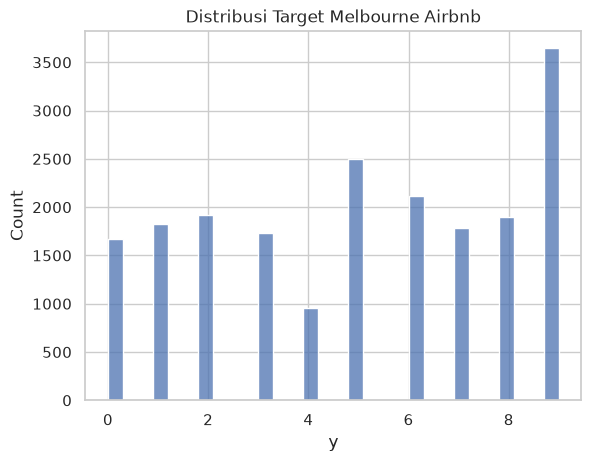

In [28]:
display(df_airbnb.describe().T)
sns.histplot(data=df_airbnb, x='y', bins=30)
plt.title('Distribusi Target Melbourne Airbnb'); plt.show()

### Distribusi fitur dan korelasi

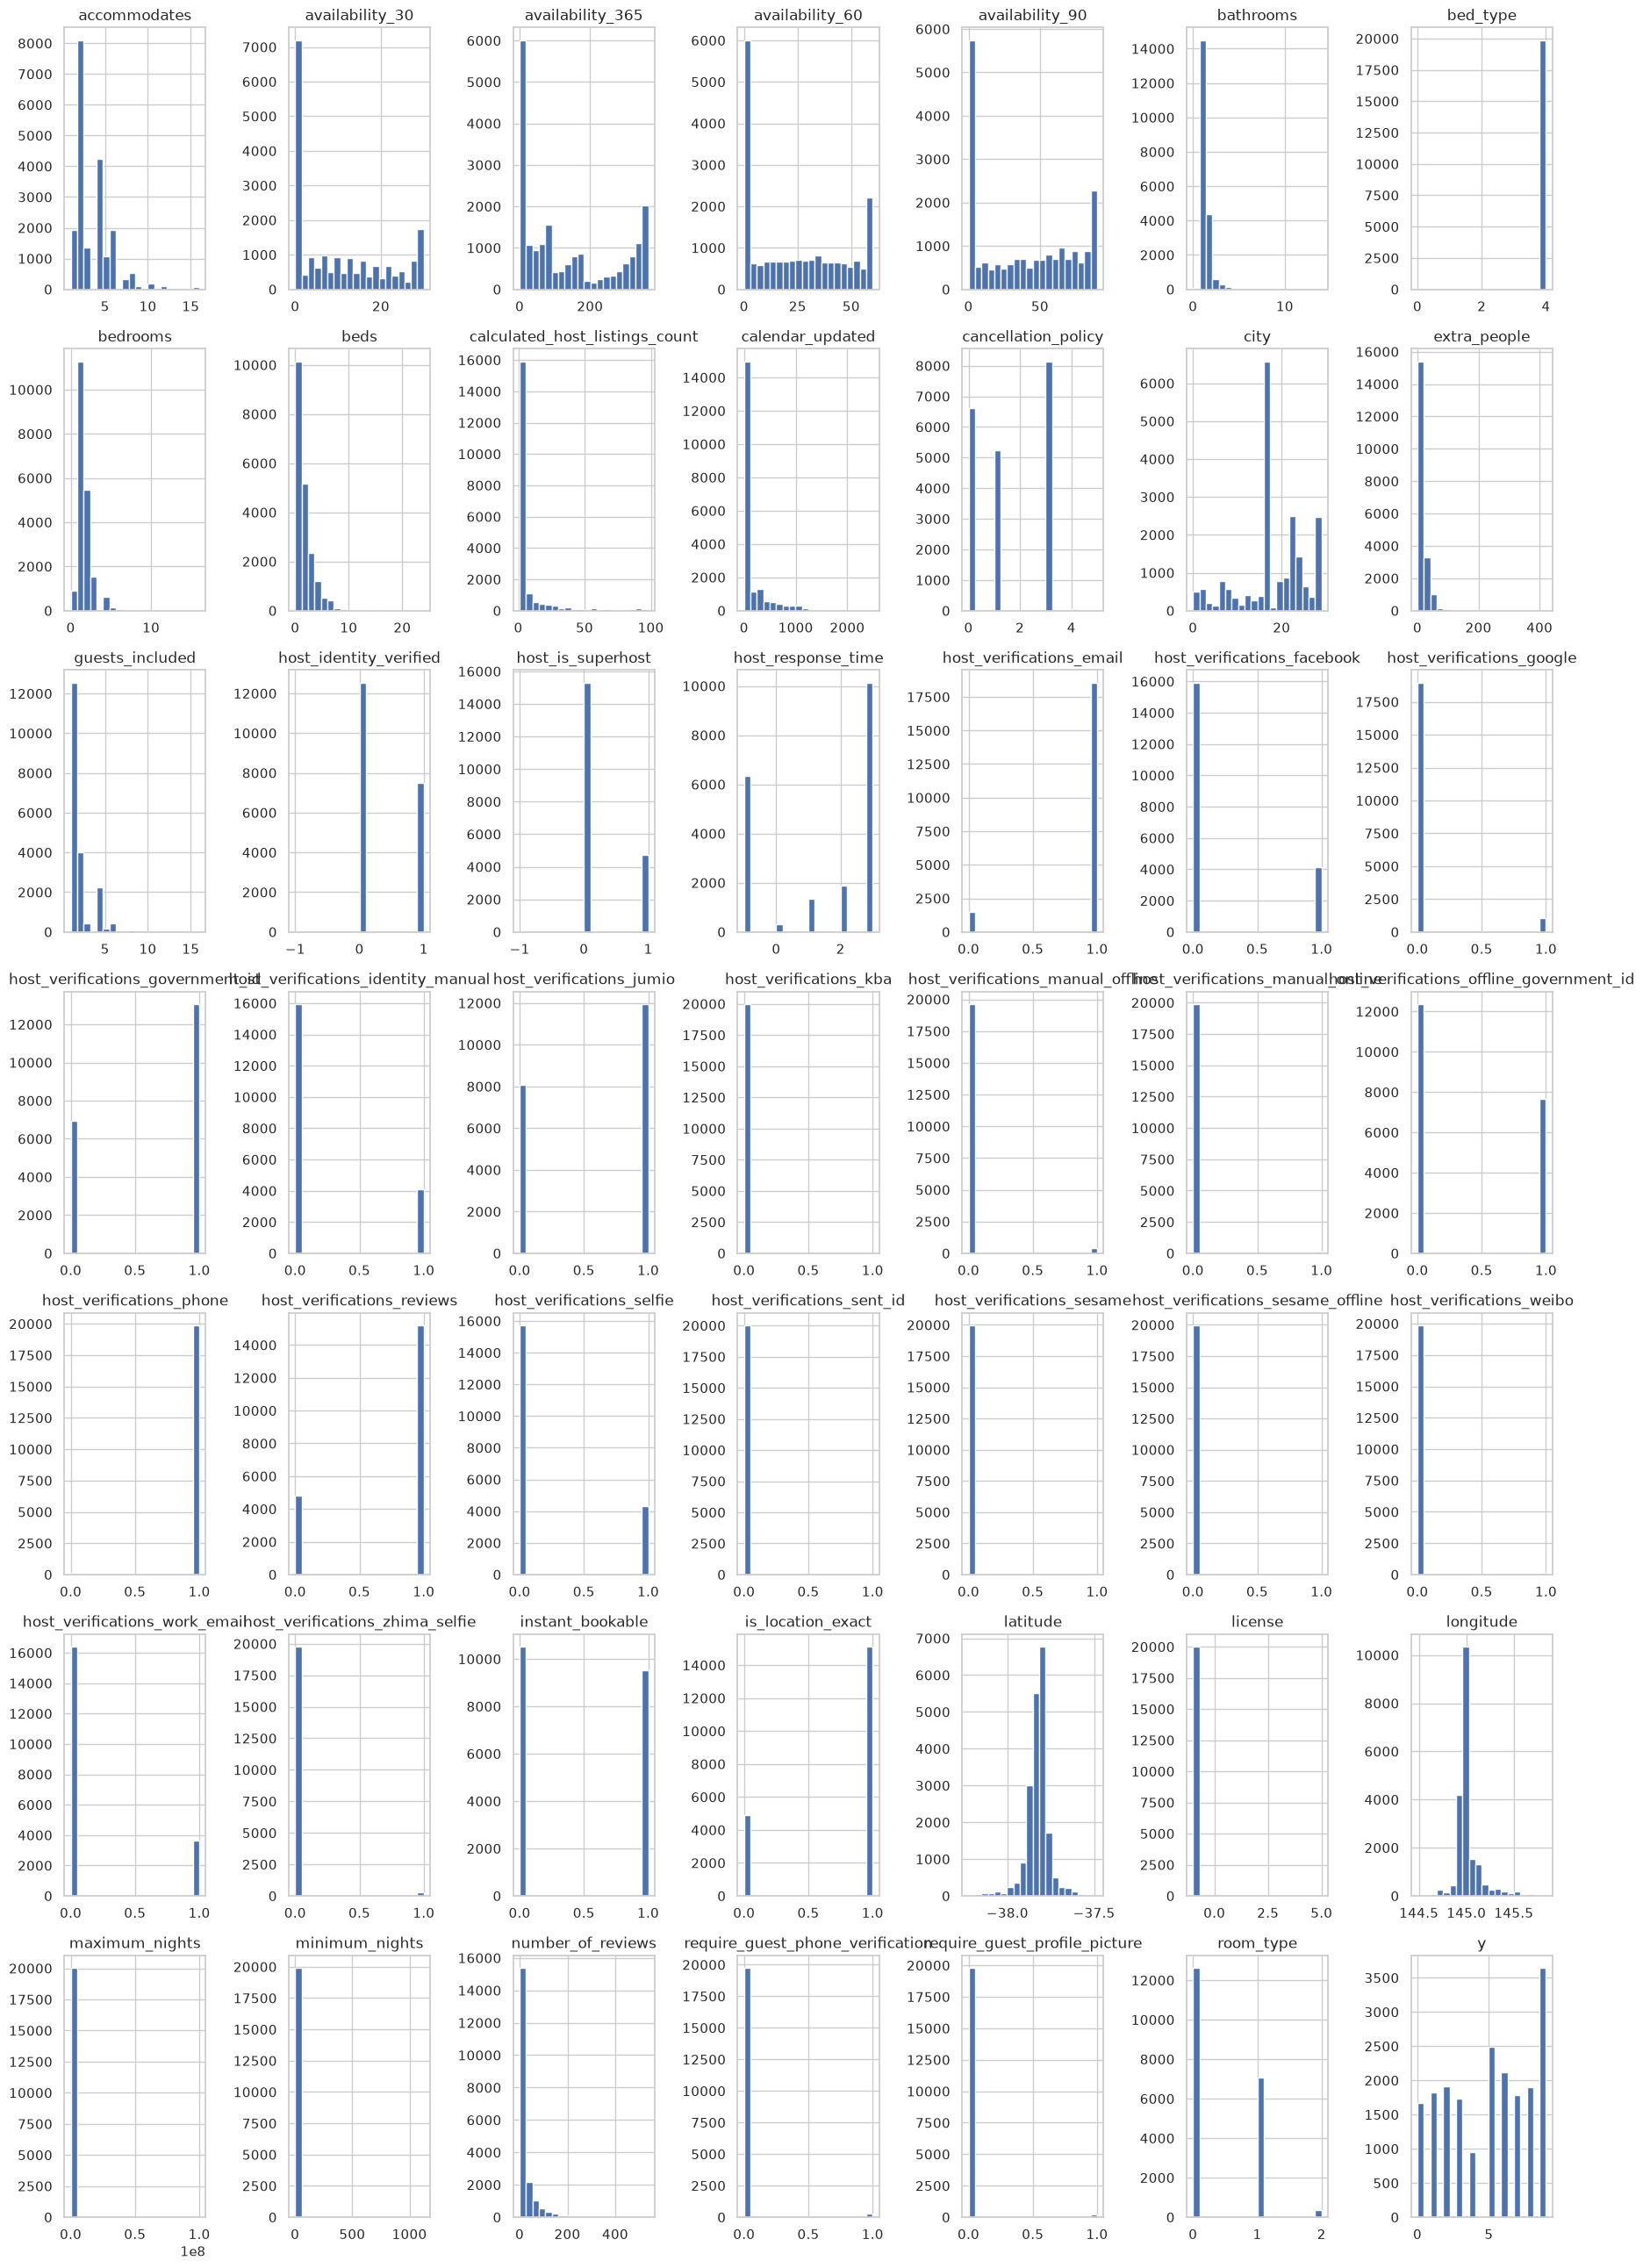

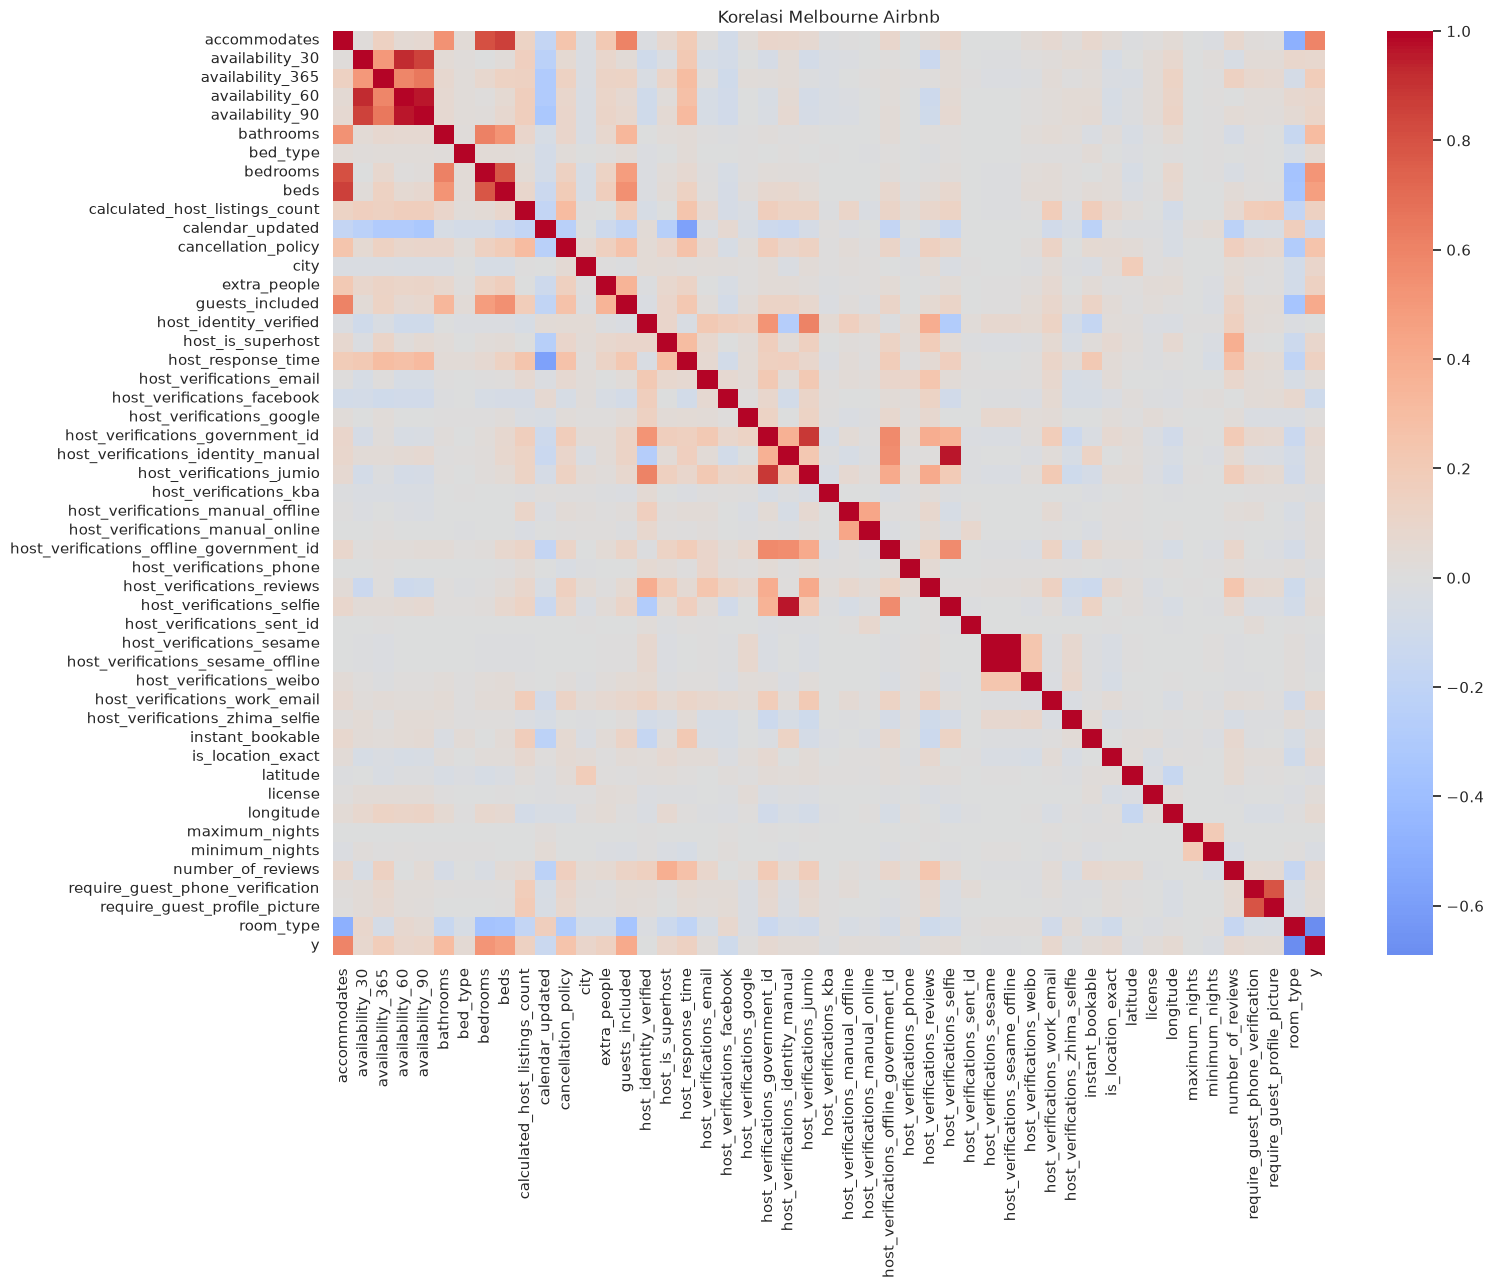

In [29]:
df_airbnb.hist(figsize=(18, 26), bins=20)
plt.tight_layout(); plt.show()
plt.figure(figsize=(16, 12))
sns.heatmap(df_airbnb.corr(numeric_only=True), cmap='coolwarm', center=0)
plt.title('Korelasi Melbourne Airbnb'); plt.show()

## 2. Student Performance

Performa akademik siswa, Targetnya tingkat nilai akhir siswa.

In [22]:
print('Ukuran:', df_student.shape)
display(df_student.head())
df_student.info()

Ukuran: (662, 44)


,guardian_father,guardian_mother,guardian_other,reason_course,reason_home,reason_other,reason_reputation,Fjob_at_home,Fjob_health,Fjob_other,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,y
0,0,1,0,1,0,0,0,0,0,0,...,0,0,4,3,4,1,1,3,6,1
1,1,0,0,1,0,0,0,0,0,1,...,1,0,5,3,3,1,1,3,4,1
2,0,1,0,0,0,1,0,0,0,1,...,1,0,4,3,2,2,3,3,10,3
3,0,1,0,0,1,0,0,0,0,0,...,1,1,3,2,2,1,1,5,2,6
4,1,0,0,0,1,0,0,0,0,1,...,0,0,4,3,2,1,2,5,4,3


<class 'pandas.DataFrame'>
RangeIndex: 662 entries, 0 to 661
Data columns (total 44 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   guardian_father    662 non-null    int64
 1   guardian_mother    662 non-null    int64
 2   guardian_other     662 non-null    int64
 3   reason_course      662 non-null    int64
 4   reason_home        662 non-null    int64
 5   reason_other       662 non-null    int64
 6   reason_reputation  662 non-null    int64
 7   Fjob_at_home       662 non-null    int64
 8   Fjob_health        662 non-null    int64
 9   Fjob_other         662 non-null    int64
 10  Fjob_services      662 non-null    int64
 11  Fjob_teacher       662 non-null    int64
 12  Mjob_at_home       662 non-null    int64
 13  Mjob_health        662 non-null    int64
 14  Mjob_other         662 non-null    int64
 15  Mjob_services      662 non-null    int64
 16  Mjob_teacher       662 non-null    int64
 17  school             662 non-

### Kualitas data

In [23]:
display(df_student.isna().sum().rename('missing').to_frame())
print('Duplikat:', df_student.duplicated().sum())

,missing
guardian_father,0
guardian_mother,0
guardian_other,0
reason_course,0
reason_home,0
reason_other,0
reason_reputation,0
Fjob_at_home,0
Fjob_health,0
Fjob_other,0


Duplikat: 0


### Statistik dan distribusi target

,count,mean,std,min,25%,50%,75%,max
guardian_father,662.0,0.229607,0.420898,0.0,0.0,0.0,0.0,1.0
guardian_mother,662.0,0.684290,0.465149,0.0,0.0,1.0,1.0,1.0
guardian_other,662.0,0.086103,0.280728,0.0,0.0,0.0,0.0,1.0
reason_course,662.0,0.435045,0.496138,0.0,0.0,0.0,1.0,1.0
reason_home,662.0,0.228097,0.419923,0.0,0.0,0.0,0.0,1.0
reason_other,662.0,0.111782,0.315337,0.0,0.0,0.0,0.0,1.0
reason_reputation,662.0,0.225076,0.417948,0.0,0.0,0.0,0.0,1.0
Fjob_at_home,662.0,0.069486,0.254472,0.0,0.0,0.0,0.0,1.0
Fjob_health,662.0,0.036254,0.187062,0.0,0.0,0.0,0.0,1.0
Fjob_other,662.0,0.563444,0.496334,0.0,0.0,1.0,1.0,1.0


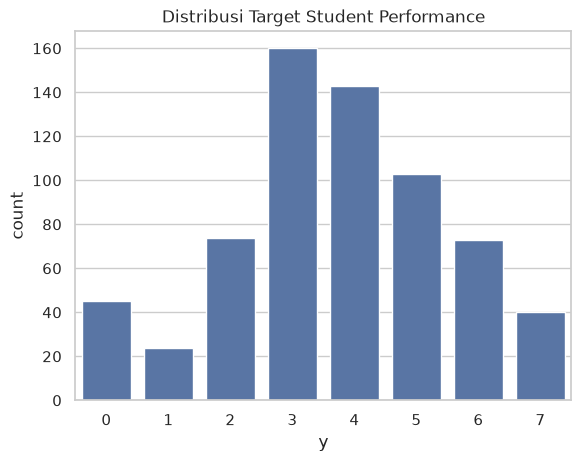

In [24]:
display(df_student.describe().T)
sns.countplot(data=df_student, x='y')
plt.title('Distribusi Target Student Performance'); plt.show()

### Distribusi fitur dan korelasi

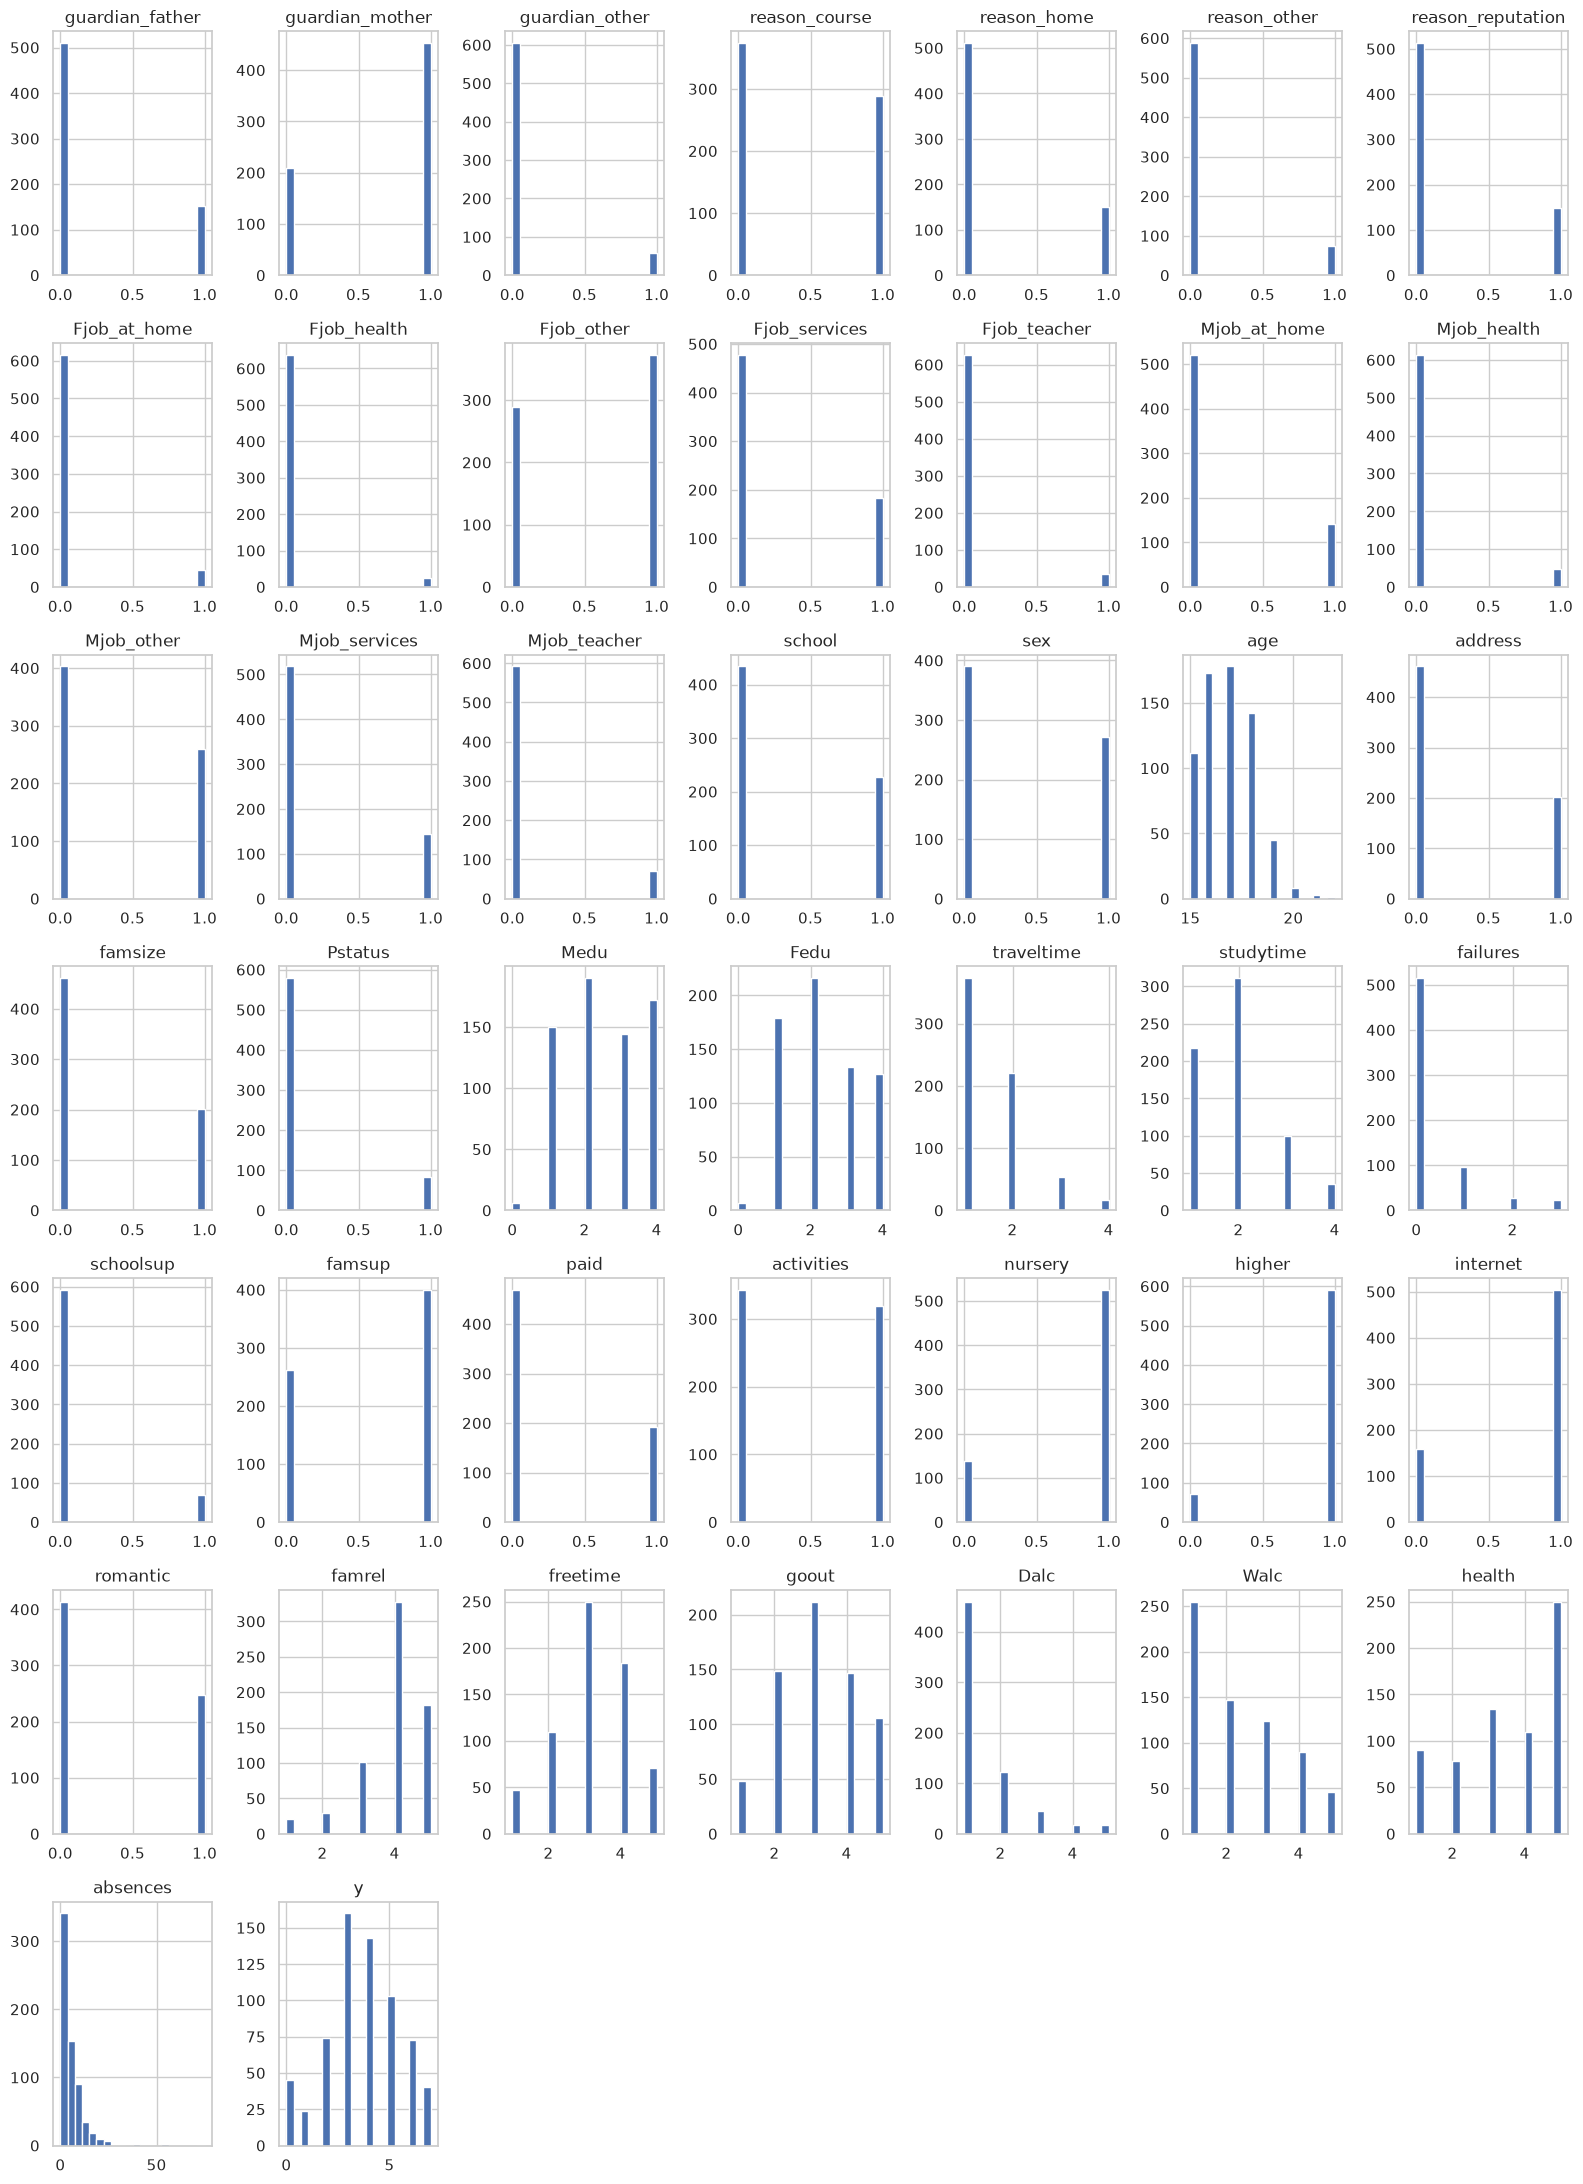

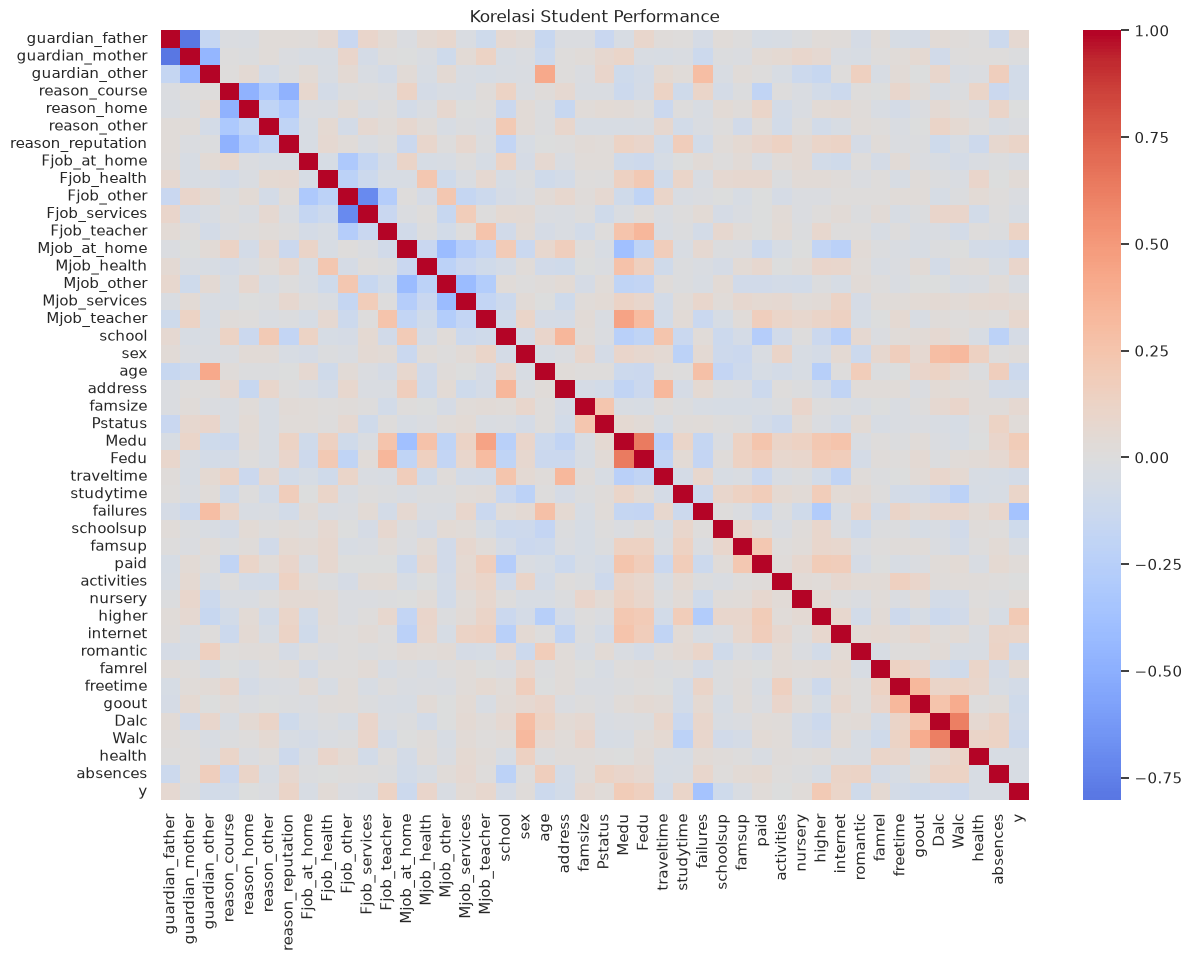

In [25]:
df_student.hist(figsize=(16, 22), bins=20)
plt.tight_layout(); plt.show()
plt.figure(figsize=(14, 10))
sns.heatmap(df_student.corr(numeric_only=True), cmap='coolwarm', center=0)
plt.title('Korelasi Student Performance'); plt.show()

## 3. NHANES

Data kesehatan dan demografi responden, targetnya status kesehatan umum

In [14]:
print('Ukuran:', df_nhanes.shape)
display(df_nhanes.head())
df_nhanes.info()

Ukuran: (5223, 31)


,x_0,x_1,x_2,x_3,x_4,x_5,x_6,x_7,x_8,x_9,...,x_21,x_22,x_23,x_24,x_25,x_26,x_27,x_28,x_29,y
0,2.0,2.0,2.0,1.0,1.0,63.0,764.0,765.0,4.0,1.0,...,1.0,2.0,2.0,1.0,2.0,7750.960967,7851.548119,2.0,67.0,0
1,2.0,2.0,2.0,1.0,2.0,43.0,520.0,521.0,3.0,1.0,...,1.0,2.0,2.0,1.0,2.0,80250.366559,82537.635085,2.0,68.0,0
2,2.0,2.0,2.0,2.0,1.0,35.0,423.0,424.0,5.0,5.0,...,1.0,2.0,2.0,1.0,2.0,77499.847246,79515.783969,2.0,67.0,0
3,1.0,2.0,1.0,1.0,1.0,52.0,625.0,625.0,3.0,1.0,...,1.0,2.0,2.0,1.0,2.0,30452.298415,31708.884317,2.0,65.0,0
4,1.0,2.0,2.0,1.0,2.0,16.0,194.0,195.0,1.0,1.0,...,1.0,2.0,2.0,1.0,2.0,10159.925574,10351.074548,1.0,70.0,0


<class 'pandas.DataFrame'>
RangeIndex: 5223 entries, 0 to 5222
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x_0     5223 non-null   float64
 1   x_1     5223 non-null   float64
 2   x_2     5223 non-null   float64
 3   x_3     5223 non-null   float64
 4   x_4     5223 non-null   float64
 5   x_5     5223 non-null   float64
 6   x_6     5223 non-null   float64
 7   x_7     5223 non-null   float64
 8   x_8     5223 non-null   float64
 9   x_9     5223 non-null   float64
 10  x_10    5223 non-null   float64
 11  x_11    5223 non-null   float64
 12  x_12    5223 non-null   float64
 13  x_13    5223 non-null   float64
 14  x_14    5223 non-null   float64
 15  x_15    5223 non-null   float64
 16  x_16    5223 non-null   float64
 17  x_17    5223 non-null   float64
 18  x_18    5223 non-null   float64
 19  x_19    5223 non-null   float64
 20  x_20    5223 non-null   float64
 21  x_21    5223 non-null   float64
 22  x_22    522

### Kualitas data

In [15]:
display(df_nhanes.isna().sum().rename('missing').to_frame())
print('Duplikat:', df_nhanes.duplicated().sum())

,missing
x_0,0
x_1,0
x_2,0
x_3,0
x_4,0
x_5,0
x_6,0
x_7,0
x_8,0
x_9,0


Duplikat: 0


### Statistik dan distribusi target

,count,mean,std,min,25%,50%,75%,max
x_0,5223.0,1.833429,0.527505,1.000000e+00,2.000000,2.000000,2.000000,9.000000
x_1,5223.0,1.905993,0.326549,1.000000e+00,2.000000,2.000000,2.000000,9.000000
x_2,5223.0,1.965920,0.359777,1.000000e+00,2.000000,2.000000,2.000000,9.000000
x_3,5223.0,1.545280,0.497993,1.000000e+00,1.000000,2.000000,2.000000,2.000000
x_4,5223.0,1.497607,0.500042,1.000000e+00,1.000000,1.000000,2.000000,2.000000
x_5,5223.0,42.921310,19.653708,1.100000e+01,25.000000,43.000000,60.000000,79.000000
x_6,5223.0,520.444955,235.908683,1.420000e+02,309.000000,521.000000,726.000000,958.000000
x_7,5223.0,521.271683,235.888605,1.440000e+02,309.500000,522.000000,727.000000,959.000000
x_8,5223.0,2.816963,1.095149,1.000000e+00,2.000000,3.000000,4.000000,5.000000
x_9,5223.0,1.503733,1.127600,1.000000e+00,1.000000,1.000000,1.000000,5.000000


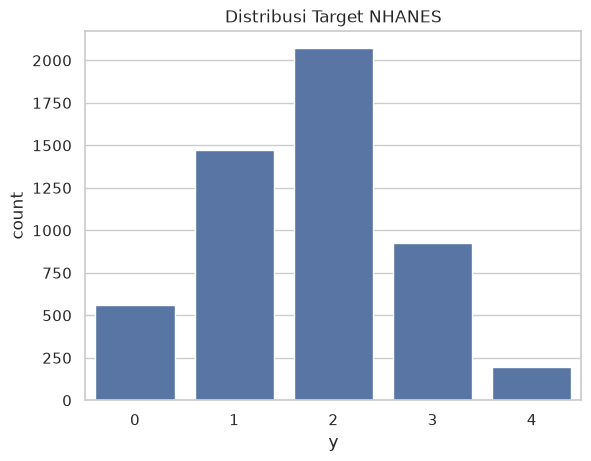

In [16]:
display(df_nhanes.describe().T)
sns.countplot(data=df_nhanes, x='y')
plt.title('Distribusi Target NHANES'); plt.show()

### Distribusi fitur dan korelasi

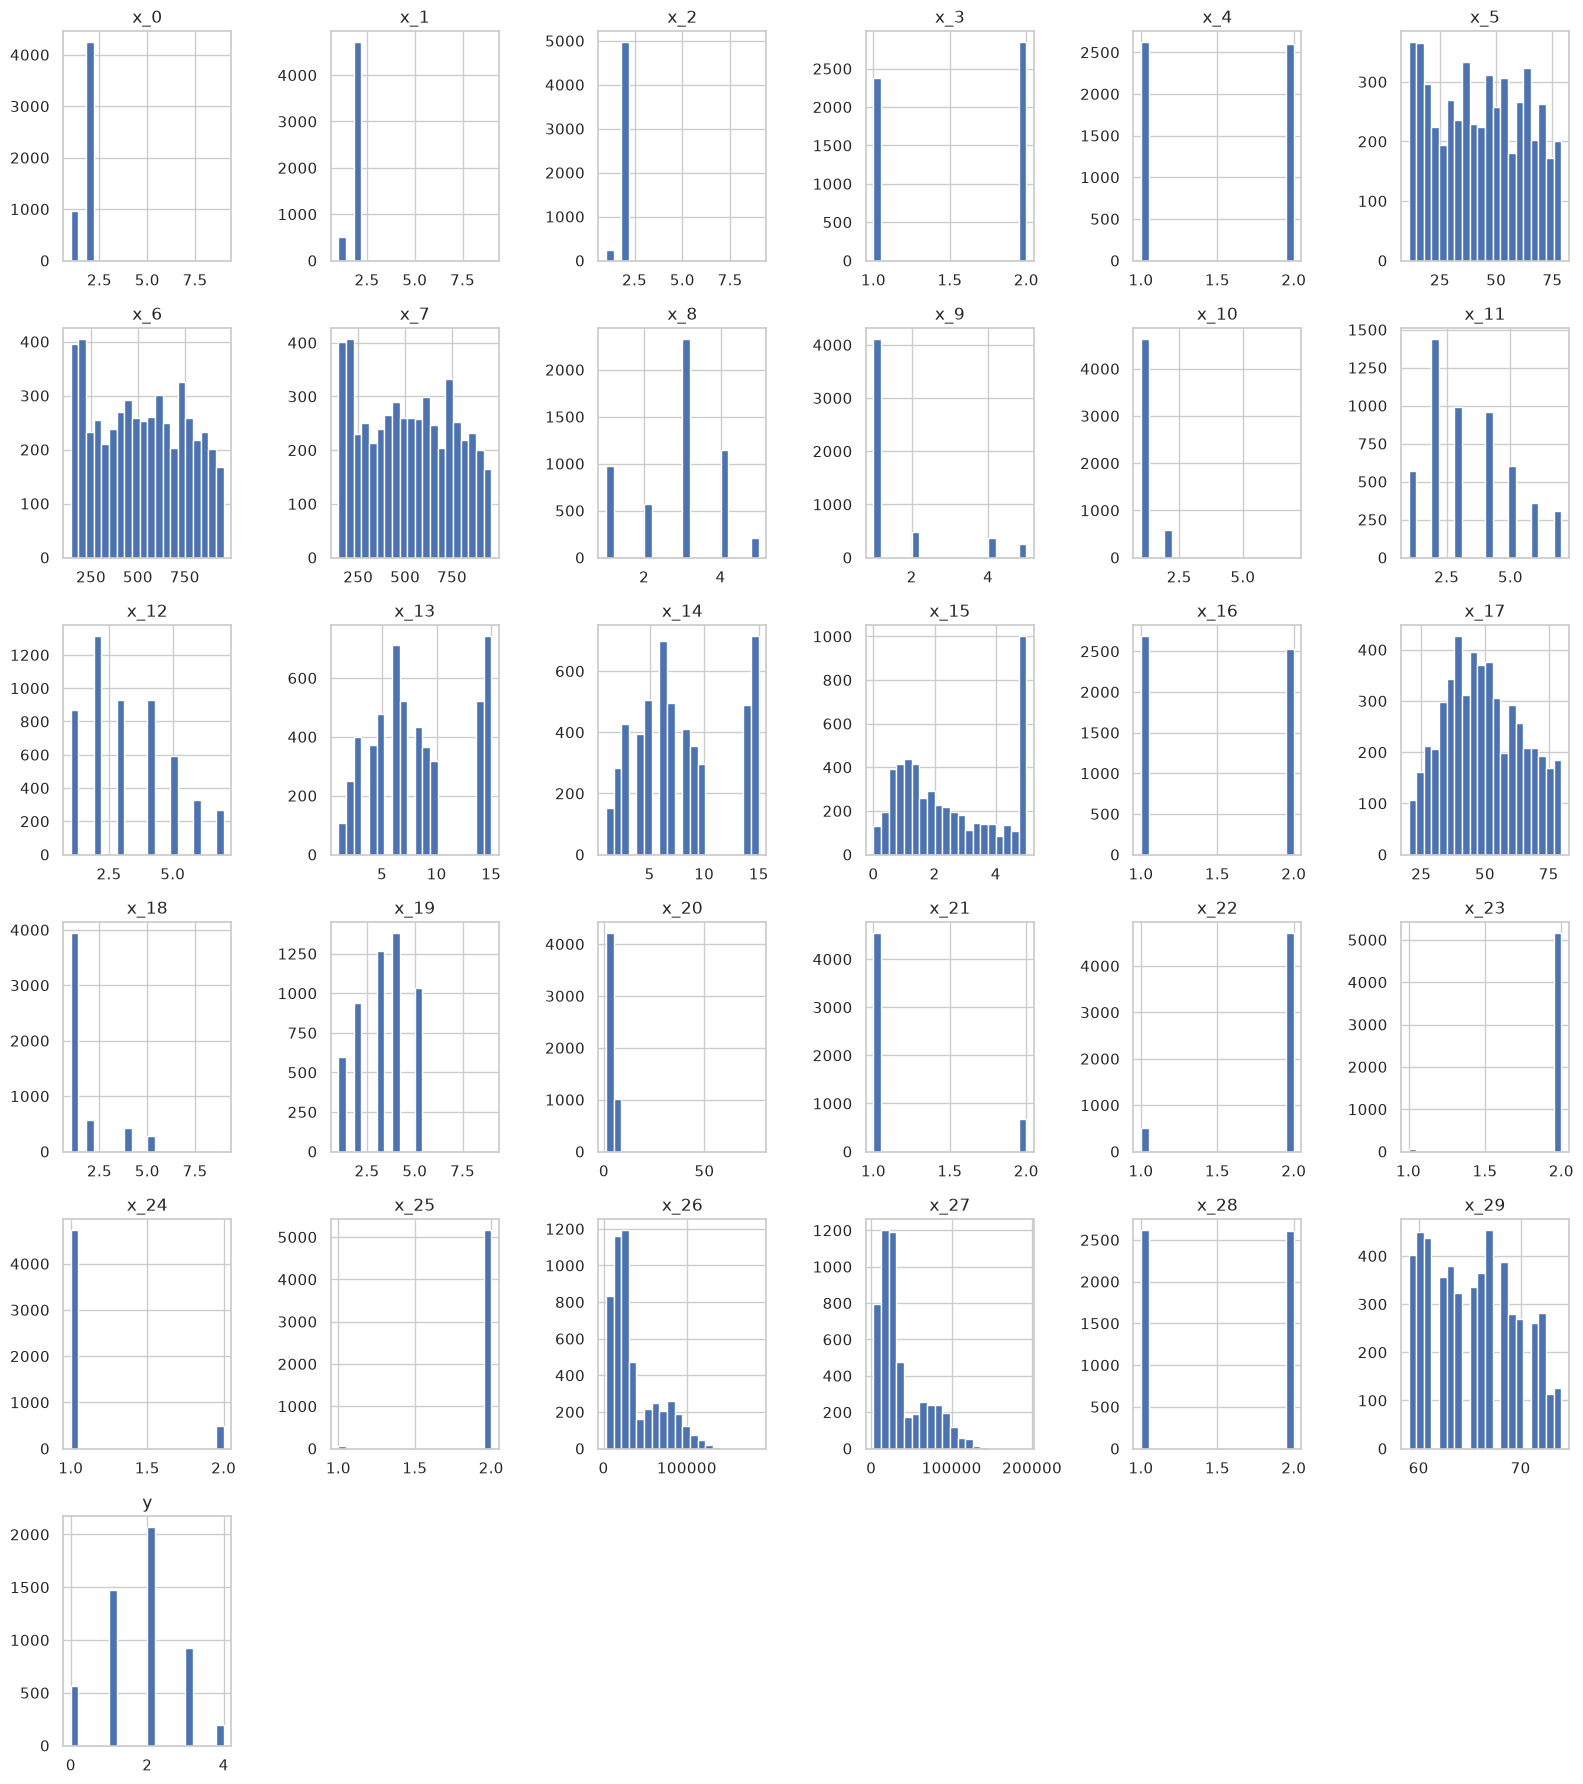

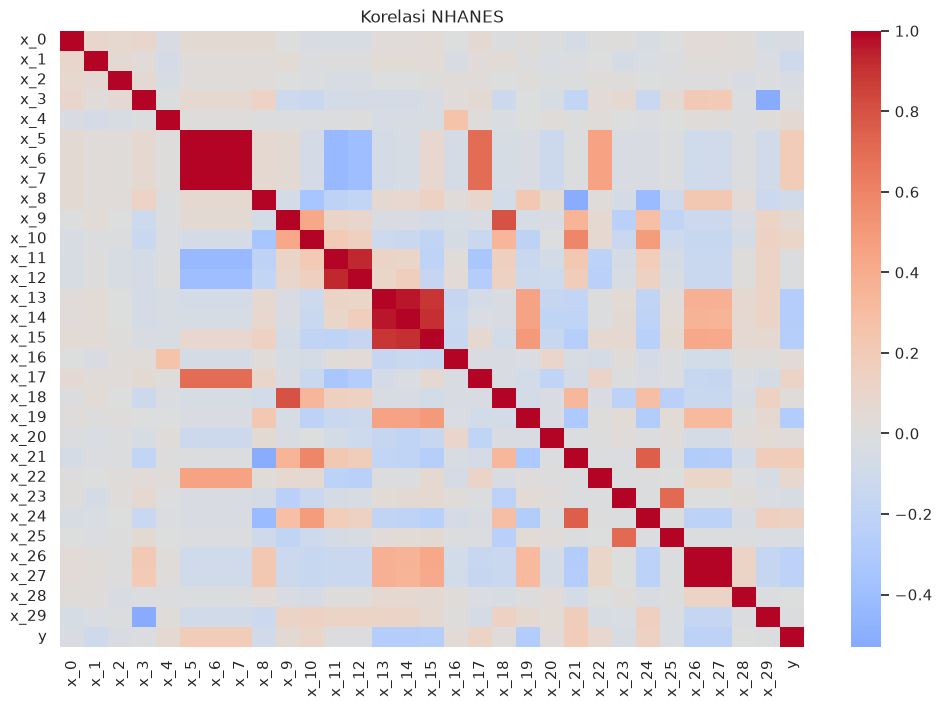

In [17]:
df_nhanes.hist(figsize=(16, 18), bins=20)
plt.tight_layout(); plt.show()
plt.figure(figsize=(12, 8))
sns.heatmap(df_nhanes.corr(numeric_only=True), cmap='coolwarm', center=0)
plt.title('Korelasi NHANES'); plt.show()

## 4. ESL

Seleksi kandidat kerja, Targetnya status kesehatan umum

In [18]:
print('Ukuran:', df_esl.shape)
display(df_esl.head())
df_esl.info()

Ukuran: (488, 5)


,x_0,x_1,x_2,x_3,y
0,5.0,4.0,3.0,2.0,0
1,3.0,2.0,2.0,6.0,0
2,2.0,1.0,2.0,4.0,0
3,4.0,2.0,3.0,4.0,0
4,2.0,2.0,2.0,4.0,0


<class 'pandas.DataFrame'>
RangeIndex: 488 entries, 0 to 487
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x_0     488 non-null    float64
 1   x_1     488 non-null    float64
 2   x_2     488 non-null    float64
 3   x_3     488 non-null    float64
 4   y       488 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 19.2 KB


### Kualitas data

In [19]:
display(df_esl.isna().sum().rename('missing').to_frame())
print('Duplikat:', df_esl.duplicated().sum())

,missing
x_0,0
x_1,0
x_2,0
x_3,0
y,0


Duplikat: 229


### Statistik dan distribusi target

,count,mean,std,min,25%,50%,75%,max
x_0,488.0,5.506148,1.525944,0.0,4.75,6.0,6.0,9.0
x_1,488.0,5.084016,1.551018,0.0,4.00,5.0,6.0,9.0
x_2,488.0,5.344262,1.135722,2.0,5.00,5.0,6.0,8.0
x_3,488.0,5.610656,0.937497,2.0,5.00,6.0,6.0,8.0
y,488.0,2.254098,1.333883,0.0,1.00,2.0,3.0,5.0


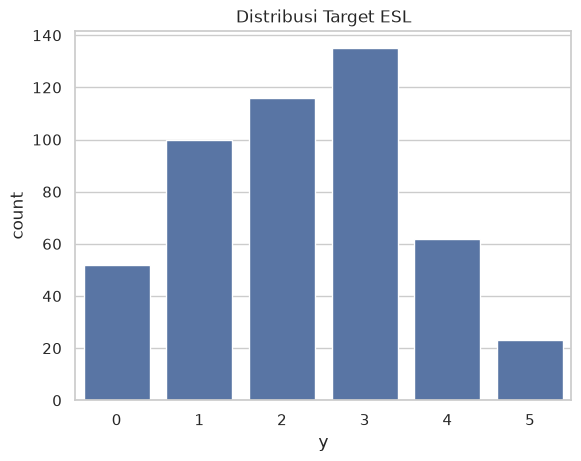

In [20]:
display(df_esl.describe().T)
sns.countplot(data=df_esl, x='y')
plt.title('Distribusi Target ESL'); plt.show()

### Distribusi fitur dan korelasi

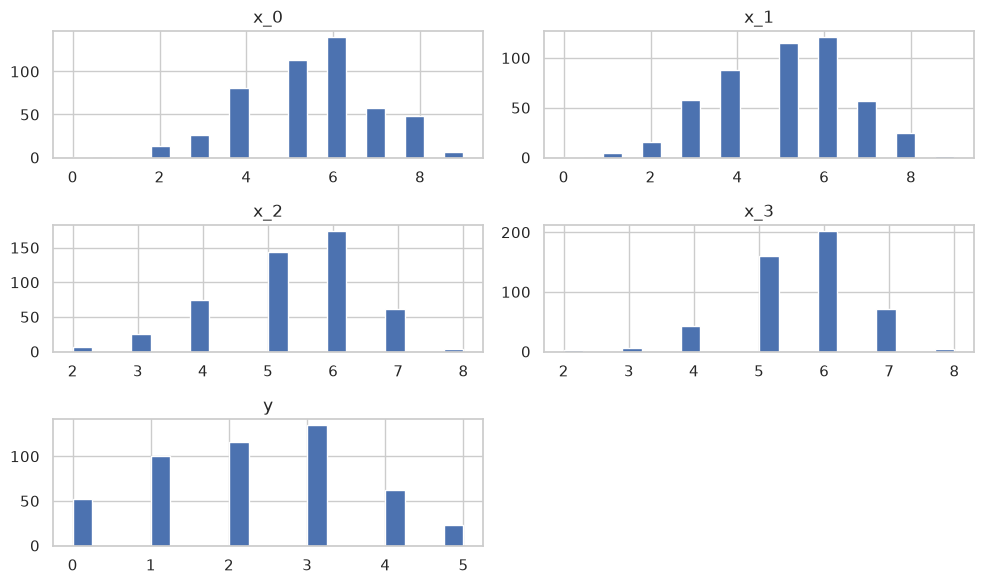

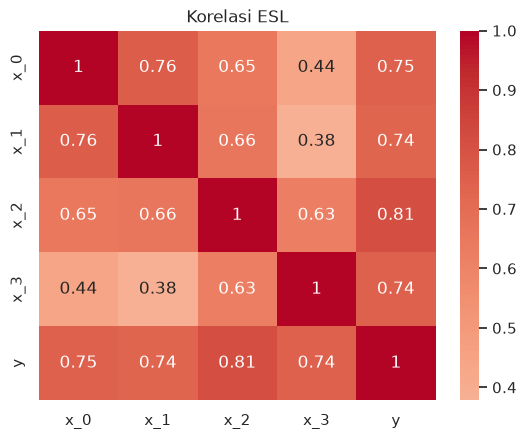

In [21]:
df_esl.hist(figsize=(10, 6), bins=20)
plt.tight_layout(); plt.show()
sns.heatmap(df_esl.corr(numeric_only=True), annot=True, cmap='coolwarm', center=0)
plt.title('Korelasi ESL'); plt.show()

## 5. LEV

Evaluasi performa dosen, Targetnya tingkat performa dosen

In [10]:
print('Ukuran:', df_lev.shape)
display(df_lev.head())
df_lev.info()

Ukuran: (1000, 5)


,x_0,x_1,x_2,x_3,y
0,0.0,2.0,0.0,1.0,0
1,1.0,0.0,3.0,1.0,0
2,2.0,4.0,3.0,2.0,0
3,1.0,0.0,1.0,1.0,0
4,1.0,0.0,1.0,1.0,0


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x_0     1000 non-null   float64
 1   x_1     1000 non-null   float64
 2   x_2     1000 non-null   float64
 3   x_3     1000 non-null   float64
 4   y       1000 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 39.2 KB


### Kualitas data

Pemeriksaan ini menunjukkan missing value dan baris duplikat.

In [11]:
display(df_lev.isna().sum().rename('missing').to_frame())
print('Duplikat:', df_lev.duplicated().sum())

,missing
x_0,0
x_1,0
x_2,0
x_3,0
y,0


Duplikat: 757


### Statistik dan distribusi target

Statistik numerik membantu melihat skala fitur, sedangkan distribusi `y` menunjukkan keseimbangan kelas.

,count,mean,std,min,25%,50%,75%,max
x_0,1000.0,1.722,1.357409,0.0,0.0,2.0,3.0,4.0
x_1,1000.0,1.985,1.358905,0.0,1.0,2.0,3.0,4.0
x_2,1000.0,2.127,1.418056,0.0,1.0,2.0,3.0,4.0
x_3,1000.0,1.985,1.377924,0.0,1.0,2.0,3.0,4.0
y,1000.0,1.785,0.954823,0.0,1.0,2.0,2.0,4.0


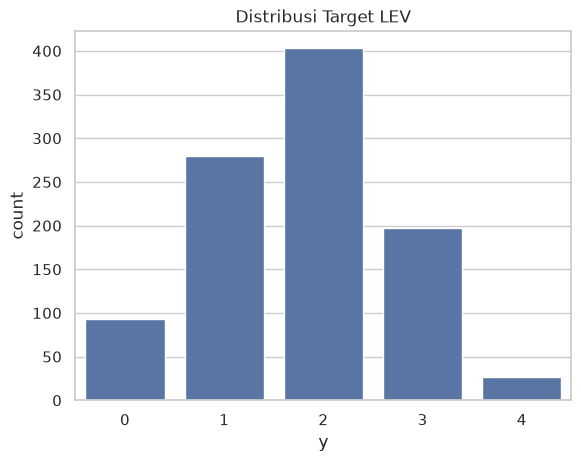

In [12]:
display(df_lev.describe().T)
sns.countplot(data=df_lev, x='y')
plt.title('Distribusi Target LEV'); plt.show()

### Distribusi fitur dan korelasi

Histogram memperlihatkan bentuk distribusi fitur dan heatmap menunjukkan hubungan linear antarvariabel.

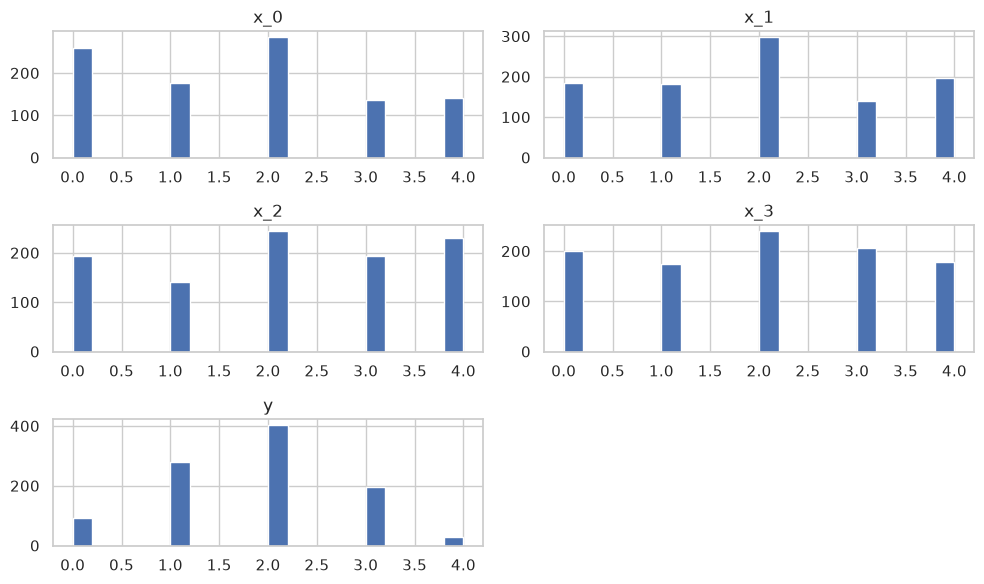

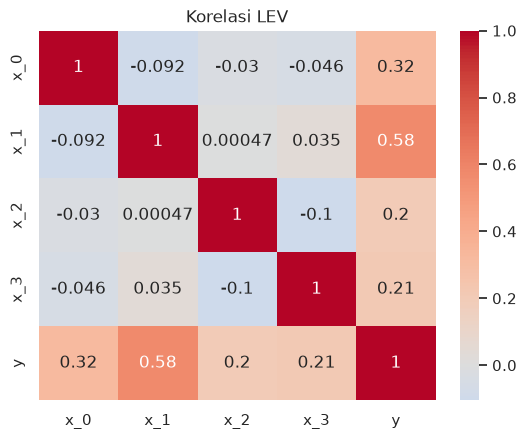

In [13]:
df_lev.hist(figsize=(10, 6), bins=20)
plt.tight_layout(); plt.show()
sns.heatmap(df_lev.corr(numeric_only=True), annot=True, cmap='coolwarm', center=0)
plt.title('Korelasi LEV'); plt.show()